# Inference of baseline models: 1nn , 3nn, ncc

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data_loader import load_svhn_data
from features import extract_flattened, extract_pca, extract_resnet_embeddings
from baselines import evaluate_baselines_on_features


X_train, y_train, X_test, y_test = load_svhn_data(n_train=15000, n_test=3000)

Loading SVHN Dataset


100%|██████████| 182M/182M [00:19<00:00, 9.15MB/s] 
100%|██████████| 64.3M/64.3M [00:08<00:00, 7.23MB/s]


Dataset Loaded. Train: (15000, 3, 32, 32), Test: (3000, 3, 32, 32)


## Vizualization of the dataset

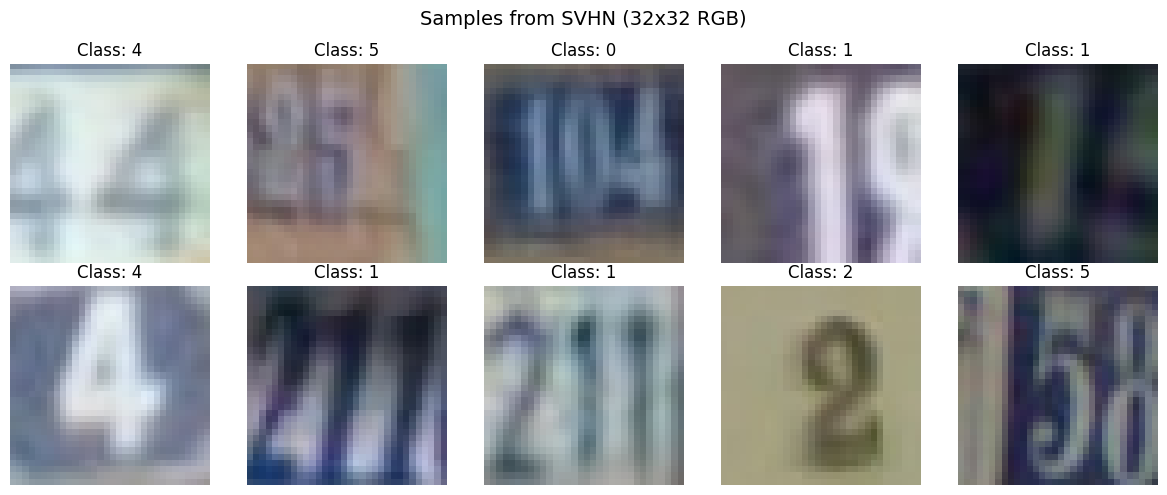

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Samples from SVHN (32x32 RGB)", fontsize=14)

for i, ax in enumerate(axes.flat):
    img = np.transpose(X_train[i], (1, 2, 0))
    ax.imshow(img)
    ax.set_title(f"Class: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Feature Extraction

In [3]:
# 1. Flattening (D = 3072)
X_train_flat, X_test_flat = extract_flattened(X_train, X_test, standardize=True)

# 2. PCA: Keep 95% of the variance (results in 52 components)
print("\nExtracting PCA Features (Keeping 95% of variance)...")
X_train_pca, X_test_pca, pca_model = extract_pca(X_train_flat, X_test_flat, n_components=0.95)

# 3. ResNet18 Embeddings (D = 512)
print("\nExtracting ResNet18 Embeddings...")
X_train_res, X_test_res = extract_resnet_embeddings(X_train, X_test)


Extracting PCA Features (Keeping 95% of variance)...

Extracting ResNet18 Embeddings...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/dimitrios-pakakis/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:05<00:00, 7.85MB/s]
ResNet Test: 100%|██████████| 24/24 [00:04<00:00,  5.55it/s]


## Baseline Models Infernece

In [7]:
all_results = []

# Experiment 1: Raw Inputs (Flattened)
res_flat, preds_flat = evaluate_baselines_on_features(
    X_train_flat, y_train, X_test_flat, y_test, "1. Flattened Pixels"
)
all_results.extend(res_flat)

# Experiment 2: PCA (95% Variance - 52 Components)
res_pca, preds_pca = evaluate_baselines_on_features(
    X_train_pca, y_train, X_test_pca, y_test, f"2. PCA ({X_train_pca.shape[1]} comp.)"
)
all_results.extend(res_pca)

# Experiment 3: ResNet18 Embeddings (512 dims)
res_resnet, preds_resnet = evaluate_baselines_on_features(
    X_train_res, y_train, X_test_res, y_test, "3. ResNet18 Features"
)
all_results.extend(res_resnet)

# Aggregate Results Table
df_baselines = pd.DataFrame(all_results)
df_baselines.to_csv("../results/midterm_baselines_comparison.csv", index=False)
display(df_baselines)


--- Evaluating Baselines for: 1. Flattened Pixels (Dimensions D=3072) ---
Nearest Class Centroid (NCC)   | Test Acc: 10.30% | Fit: 0.416s | Predict: 0.03s
1-Nearest Neighbor (1-NN)      | Test Acc: 36.03% | Fit: 0.014s | Predict: 2.30s
3-Nearest Neighbors (3-NN)     | Test Acc: 36.40% | Fit: 0.016s | Predict: 2.44s

--- Evaluating Baselines for: 2. PCA (53 comp.) (Dimensions D=53) ---
Nearest Class Centroid (NCC)   | Test Acc: 10.37% | Fit: 0.010s | Predict: 0.00s
1-Nearest Neighbor (1-NN)      | Test Acc: 36.07% | Fit: 0.005s | Predict: 0.14s
3-Nearest Neighbors (3-NN)     | Test Acc: 36.83% | Fit: 0.002s | Predict: 0.07s

--- Evaluating Baselines for: 3. ResNet18 Features (Dimensions D=512) ---
Nearest Class Centroid (NCC)   | Test Acc: 36.30% | Fit: 0.056s | Predict: 0.00s
1-Nearest Neighbor (1-NN)      | Test Acc: 31.77% | Fit: 0.003s | Predict: 0.41s
3-Nearest Neighbors (3-NN)     | Test Acc: 34.93% | Fit: 0.004s | Predict: 0.66s


,Features,Dimensions (D),Classifier,Train Accuracy (%),Test Accuracy (%),Fit Time (sec),Predict Time (sec)
0,1. Flattened Pixels,3072,Nearest Class Centroid (NCC),11.85,10.30,0.4159,0.028
1,1. Flattened Pixels,3072,1-Nearest Neighbor (1-NN),100.00,36.03,0.0143,2.305
2,1. Flattened Pixels,3072,3-Nearest Neighbors (3-NN),63.83,36.40,0.0160,2.436
3,2. PCA (53 comp.),53,Nearest Class Centroid (NCC),11.73,10.37,0.0098,0.001
4,2. PCA (53 comp.),53,1-Nearest Neighbor (1-NN),100.00,36.07,0.0045,0.143
5,2. PCA (53 comp.),53,3-Nearest Neighbors (3-NN),64.95,36.83,0.0017,0.072
6,3. ResNet18 Features,512,Nearest Class Centroid (NCC),34.83,36.30,0.0556,0.005
7,3. ResNet18 Features,512,1-Nearest Neighbor (1-NN),100.00,31.77,0.0030,0.406
8,3. ResNet18 Features,512,3-Nearest Neighbors (3-NN),61.09,34.93,0.0039,0.658


## Vizualization of Results

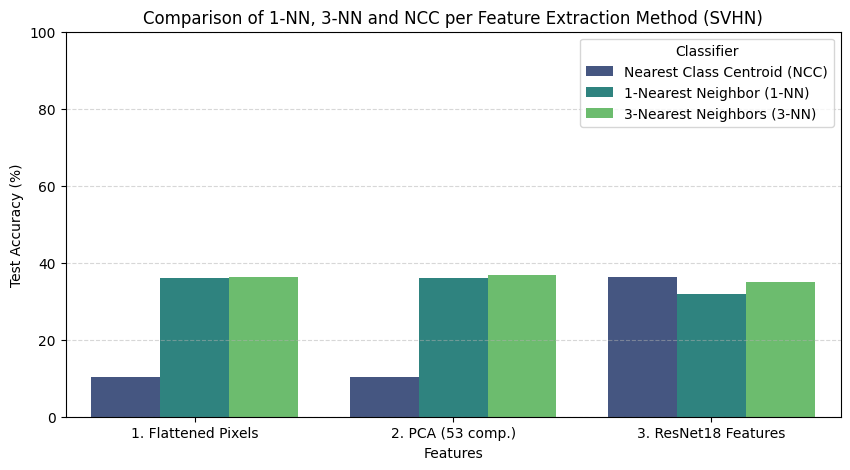

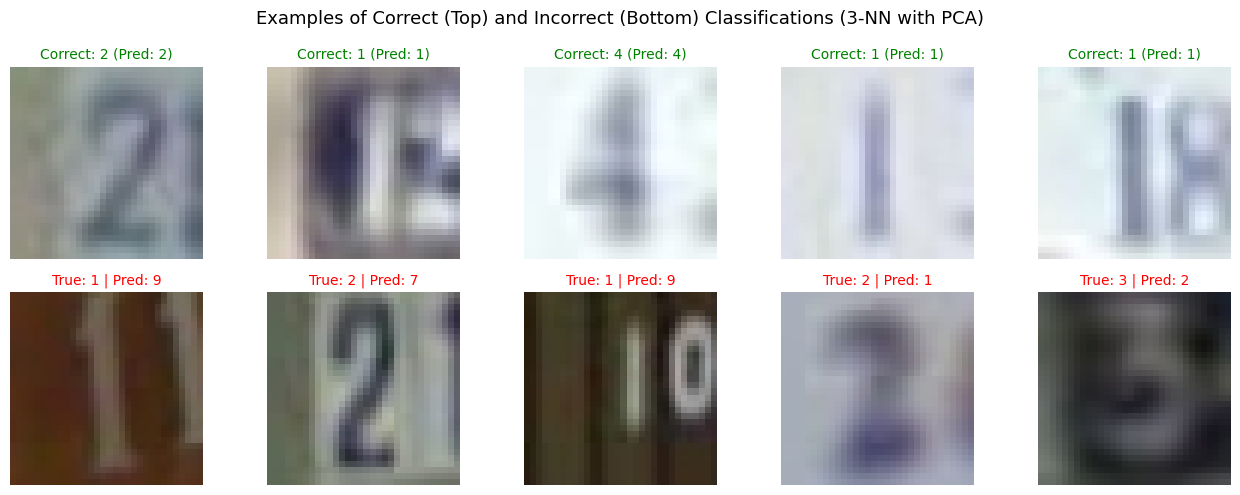

In [8]:
# Barplot comparing Test Accuracy
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_baselines, x="Features", y="Test Accuracy (%)", hue="Classifier", palette="viridis"
)
plt.title("Comparison of 1-NN, 3-NN and NCC per Feature Extraction Method (SVHN)")
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Display 5 Correct and 5 Incorrect Predictions (e.g., using 3-NN with PCA)
y_pred_sample = preds_pca["3-Nearest Neighbors (3-NN)"]
correct_idx = np.where(y_pred_sample == y_test)[0][:5]
wrong_idx = np.where(y_pred_sample != y_test)[0][:5]

fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for i, idx in enumerate(correct_idx):
    axes[0, i].imshow(np.transpose(X_test[idx], (1, 2, 0)))
    axes[0, i].set_title(f"Correct: {y_test[idx]} (Pred: {y_pred_sample[idx]})", color="green", fontsize=10)
    axes[0, i].axis("off")

for i, idx in enumerate(wrong_idx):
    axes[1, i].imshow(np.transpose(X_test[idx], (1, 2, 0)))
    axes[1, i].set_title(f"True: {y_test[idx]} | Pred: {y_pred_sample[idx]}", color="red", fontsize=10)
    axes[1, i].axis("off")

plt.suptitle("Examples of Correct (Top) and Incorrect (Bottom) Classifications (3-NN with PCA)", fontsize=13)
plt.tight_layout()
plt.show()